# 04 · The business case: volume effect vs rate compression, blanket vs targeted rollout

Read with: [`10_revenue_decomposition.md`](../docs/learn/10_revenue_decomposition.md).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from tierlift.config import REPO_ROOT, load_config
from tierlift.simulate import SimulatedData
cfg = load_config()
DATA, RESULTS, FIGS = REPO_ROOT / "data", REPO_ROOT / "results", REPO_ROOT / "reports" / "figures"
assert DATA.exists(), "run `make all` (or `tierlift run-all`) first: the notebooks read data/ and results/"
data = SimulatedData.load(DATA)
e, truth = data.experiment, data.truth.set_index("client_id")
primary, control = cfg.analysis.primary_contrast
def fig(name): display(Image(filename=str(FIGS / name), width=900))
print(f"seed {cfg.seed}, {len(e):,} clients, cells {cfg.experiment.cells}")

seed 13, 5,000 clients, cells {'holdout': 0.3, 'nudge': 0.3, 'incentive': 0.4}


## 1. ΔRevenue = volume effect + rate effect + interaction, per distance bucket

raw arm means                                                        AIPW-adjusted                                                         \
          volume_effect rate_effect  interaction         total net_revenue_pct volume_effect rate_effect  interaction         total net_revenue_pct   
10_to_20    13,361.8490 -5,492.1010  -1,220.1580    6,649.5890          0.1110   17,639.1450 -6,145.2970  -1,821.5610    9,672.2880          0.1630   
20_plus      1,434.0540 -4,708.7830    -109.9600   -3,384.6900         -0.0550    2,784.5590 -4,873.9460    -222.8800   -2,312.2670         -0.0380   
top_tier  -151,020.0470 57,152.8710 -20,700.1840 -114,567.3600         -0.2750 -170,806.9310 57,994.7190 -22,875.2420 -135,687.4540         -0.3130   
within_10      103.9490 -4,319.2970      -6.9800   -4,222.3280         -0.0660      223.1220 -5,355.8520     -18.4340   -5,151.1640         -0.0790   

                  truth                                                      
          volume_effect rate_effect interaction       total net_revenue_pct  
10_to_20    13,085.9040 -4,965.2750 -1,093.7030  7,026.9260          0.1180  
20_plus      1,551.5470 -4,083.6090   -105.1730 -2,637.2340         -0.0440  
top_tier         0.0000  7,707.0080      0.0000  7,707.0080          0.0190  
within_10    3,527.4900 -5,650.4170   -317.0920 -2,440.0190         -0.0390

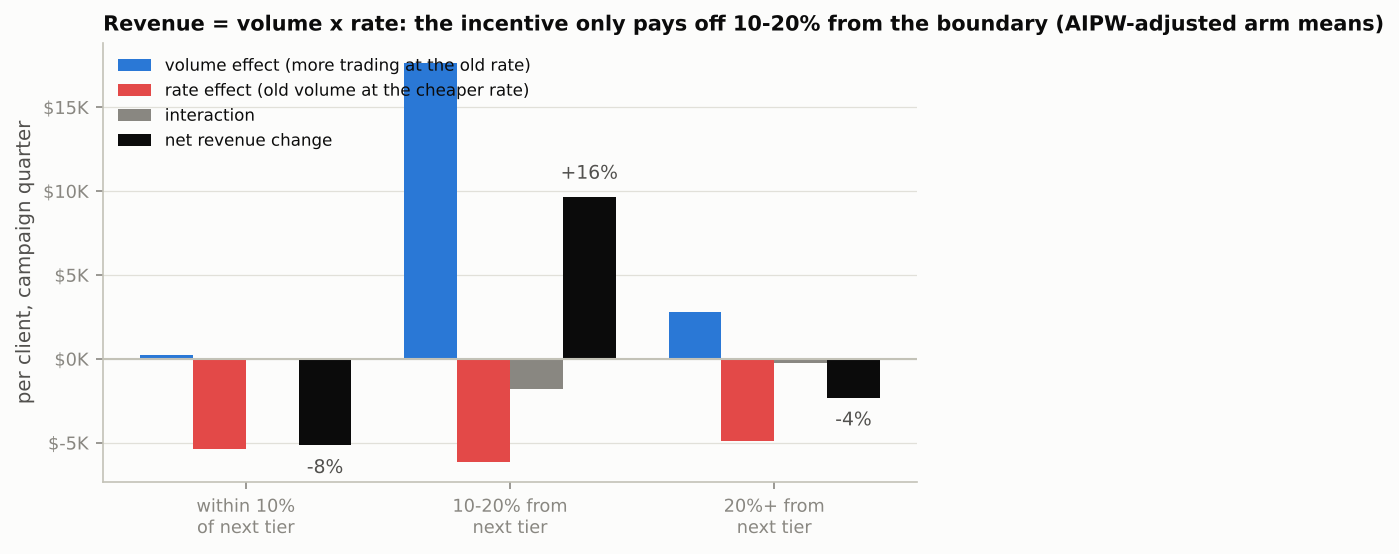

In [2]:
from tierlift.economics.decomposition import decompose_groups, decompose_true
raw = decompose_groups(e, primary)
adj = decompose_groups(e, primary, adjust=True, seed=cfg.seed)
tru = decompose_true(truth, primary, e.set_index("client_id")["distance_bucket"])
cols = ["volume_effect", "rate_effect", "interaction", "total", "net_revenue_pct"]
display(pd.concat({"raw arm means": raw[cols], "AIPW-adjusted": adj[cols], "truth": tru[cols]}, axis=1).round(3))
fig("09_revenue_decomposition.png")

## 2. Blanket vs targeted rollout, experimental estimate next to the oracle

In [3]:
from tierlift.economics.rollout import ContrastScores, rollout_table, targeting_band_grid
from tierlift.uplift.policy import rule_policy
band = cfg.analysis.targeting_band
scores = ContrastScores(e, primary, control, cfg.seed)
policies = {"Blanket rollout": np.ones(len(e), bool), f"Targeted: {band[0]:.0%}-{band[1]:.0%} from tier": rule_policy(e, band)}
roll = rollout_table(e, data.truth, policies, primary, control, cfg.seed, scores)
display(roll[["clients_targeted", "est_net_revenue_pct", "ci_low_pct", "ci_high_pct", "cuped_net_revenue_pct", "true_net_revenue_pct", "true_quarterly_impact", "true_rate_compression_cost"]])

,clients_targeted,est_net_revenue_pct,ci_low_pct,ci_high_pct,cuped_net_revenue_pct,true_net_revenue_pct,true_quarterly_impact,true_rate_compression_cost
policy,,,,,,,,
Blanket rollout,5000,-0.0343,-0.0601,-0.0084,-0.0466,-0.0297,"-9,061,171.4669","-22,230,298.1587"
Targeted: 10%-20% from tier,408,0.1245,0.0434,0.2056,0.0908,0.1183,"2,866,985.7234","-2,330,287.3409"


,n,net_revenue_pct,ci_low,ci_high
band,,,,
0%-10%,346,-0.0648,-0.1419,0.0124
10%-20%,408,0.1245,0.0434,0.2056
20%-30%,489,0.0177,-0.1105,0.1459
30%-50%,1068,-0.0568,-0.1266,0.0130
50%-100%,2678,-0.0492,-0.0736,-0.0249


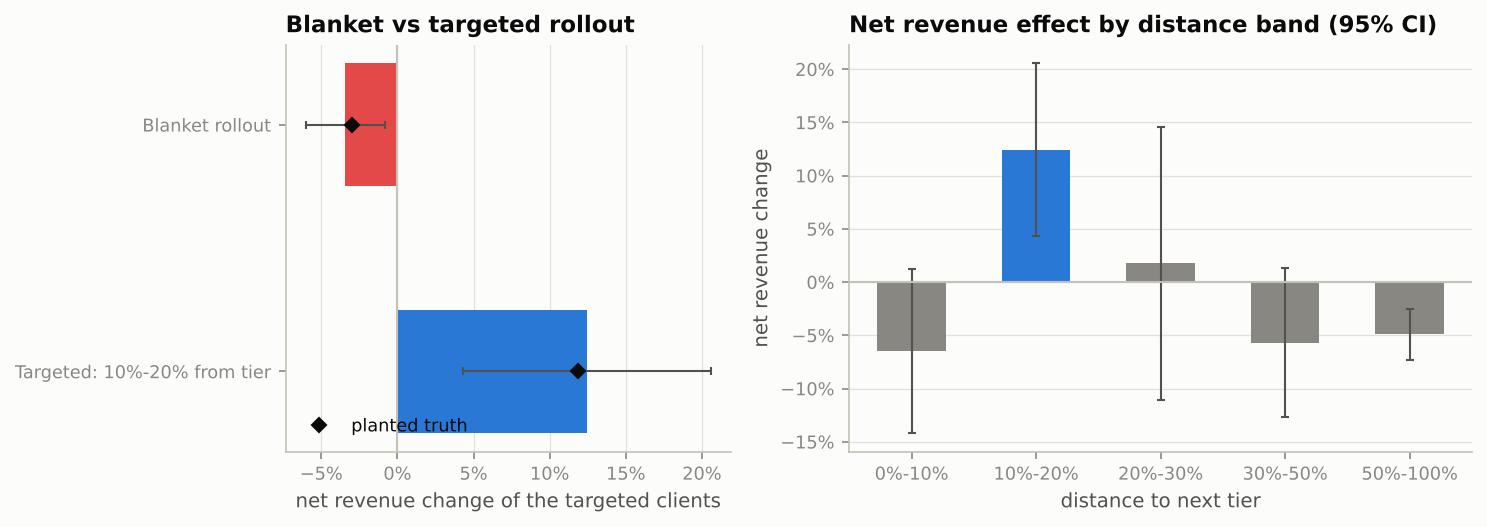

In [4]:
grid = targeting_band_grid(e, primary, [(0, 0.1), (0.1, 0.2), (0.2, 0.3), (0.3, 0.5), (0.5, 1.0)], seed=cfg.seed, scores=scores)
display(grid); fig("10_rollout_comparison.png")

## 3. Is the estimator trustworthy? 40 replications

In [5]:
display(pd.read_csv(RESULTS / "montecarlo_summary.csv", index_col=[0, 1]))
display(pd.read_csv(RESULTS / "montecarlo_extra.csv"))

n_seeds  mean_truth  mean_estimate   bias  sd_of_estimates  mean_reported_se  ci95_coverage
target  estimator                                                                                             
blanket cuped           40     -0.0291        -0.0230 0.0061           0.0284            0.0278         0.9500
        aipw            40     -0.0291        -0.0273 0.0018           0.0133            0.0136         0.9500
band    cuped           40      0.1103         0.1259 0.0156           0.1108            0.0934         0.9000
        aipw            40      0.1103         0.1297 0.0194           0.0554            0.0475         0.9500

,cuped_variance_reduction_mean,0.5091778028166691
0,cuped_variance_reduction_sd,0.0290
1,weekly_hazard_mean,0.0195
2,weekly_hazard_sd,0.0004
3,showcase_seed,13.0000


## Check your understanding

1. In the 10–20% bucket the rate effect is about −$6K per client and the volume effect about +$18K. What volume lift would make the bucket break even?
2. Why is the blanket rollout's CI so much narrower than the band's, in absolute terms, even though it is the *less* interesting number?
3. The Monte Carlo says the band estimator's mean is ≈ 2 points above the truth with 95% coverage. Is that a bug, a bias worth fixing, or expected? (Hint: ratio estimator.)